# 03 · Loading pipeline and augmentation

**Goal:** build the code that feeds images to the models, and choose the augmentations that make our small training set look bigger.

**Inputs:** the split from notebook 02 (`data/splits/*.csv`) and the NEU images.

**Outputs:** `outputs/figures/prep_01_augmentation_examples.png`, `outputs/results/pipeline_check.json`. The same pipeline code is copied into notebook 04, which trains the models.

Two input formats are needed:

| Model | Size | Channels | Pixel scale |
|---|---|---|---|
| Our CNN from scratch (M1, M2) | 200 × 200 | 1 (grayscale) | 0 to 1 |
| MobileNetV2, pretrained on ImageNet (M3) | 224 × 224 | 3 (grayscale repeated) | −1 to 1 |

MobileNetV2 learned on colour photos scaled to −1 to 1. Feeding it something else does not raise an error; it just trains badly. That is why its input goes through `mobilenet_v2.preprocess_input`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    DATA_ROOT = next(Path("/kaggle/input").rglob("NEU-DET")).parent
    SPLIT_DIR = next(Path("/kaggle/input").rglob("train.csv")).parent
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    SPLIT_DIR = PROJECT / "data" / "splits"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
for folder in (FIG_DIR, RES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
splits = {name: pd.read_csv(SPLIT_DIR / f"{name}.csv") for name in ("train", "val", "test")}
for name, part in splits.items():
    print(f"{name:5s} {len(part)} images")

train 1260 images
val   270 images
test  270 images


## The pipeline

`tf.data` reads the files in parallel, decodes them, resizes them and groups them into batches of 32 while the GPU is busy with the previous batch (`prefetch`). Labels are the class index 0 to 5, in the alphabetical order of `CLASSES`.

The test set gets the same pipeline but is not opened in this notebook.

In [2]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(part, image_size, three_channels=False, shuffle=False):
    paths = [str(DATA_ROOT / p) for p in part["filepath"]]
    labels = [CLASSES.index(c) for c in part["label"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=1)
        img = tf.image.resize(img, (image_size, image_size))
        if three_channels:
            img = tf.image.grayscale_to_rgb(img)
            img = keras.applications.mobilenet_v2.preprocess_input(img)
        else:
            img = img / 255.0
        return img, label

    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)


train_small = make_dataset(splits["train"], 200, shuffle=True)
train_imagenet = make_dataset(splits["train"], 224, three_channels=True, shuffle=True)

checks = {}
for name, ds in (("scratch_cnn", train_small), ("mobilenetv2", train_imagenet)):
    images, labels = next(iter(ds))
    checks[name] = {
        "batch_shape": images.shape.as_list(),
        "min": round(float(tf.reduce_min(images)), 3),
        "max": round(float(tf.reduce_max(images)), 3),
        "labels_in_batch": sorted(set(labels.numpy().tolist())),
    }
    print(name, checks[name])

2026-10-18 03:57:17.622136: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


scratch_cnn {'batch_shape': [32, 200, 200, 1], 'min': 0.0, 'max': 1.0, 'labels_in_batch': [0, 1, 2, 3, 4, 5]}
mobilenetv2 {'batch_shape': [32, 224, 224, 3], 'min': -0.997, 'max': 1.0, 'labels_in_batch': [0, 1, 2, 3, 4, 5]}


## Augmentation

With 210 training images per class, a CNN can memorise the training set instead of learning what a defect looks like. Augmentation shows it a slightly different version of each image in every epoch. Every choice has to make physical sense for a camera looking at a steel strip:

| Layer | Setting | Why |
|---|---|---|
| `RandomFlip` | horizontal and vertical | A defect seen in a mirror is still the same defect. |
| `RandomRotation` | ±5 % of a full turn (±18°) | Small tilts of the camera or strip. We avoid 90° turns: scratches and rolled-in scale follow the rolling direction, so a big turn makes an unrealistic image. |
| `RandomZoom` | ±10 % | Small changes in camera distance. |
| `RandomContrast` | ±20 % | Lighting changes along the line. |
| `RandomBrightness` | ±20 % | Same reason. Images are grayscale, so there is no colour jitter. |

These are Keras layers placed **inside the model**. Keras switches them on only while training, so validation and test images are never augmented.

In [3]:
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED),
    keras.layers.RandomZoom(0.1, fill_mode="reflect", seed=SEED),
    keras.layers.RandomContrast(0.2, seed=SEED),
    keras.layers.RandomBrightness(0.2, value_range=(0.0, 1.0), seed=SEED),
], name="augmentation")

`fill_mode="reflect"` fills the corners exposed by a rotation or zoom with a mirror image of the steel surface, instead of black triangles that never occur on a real strip.

Below: one training image each of crazing, rolled-in scale and scratches (the last two have a direction), then eight augmented versions of it.

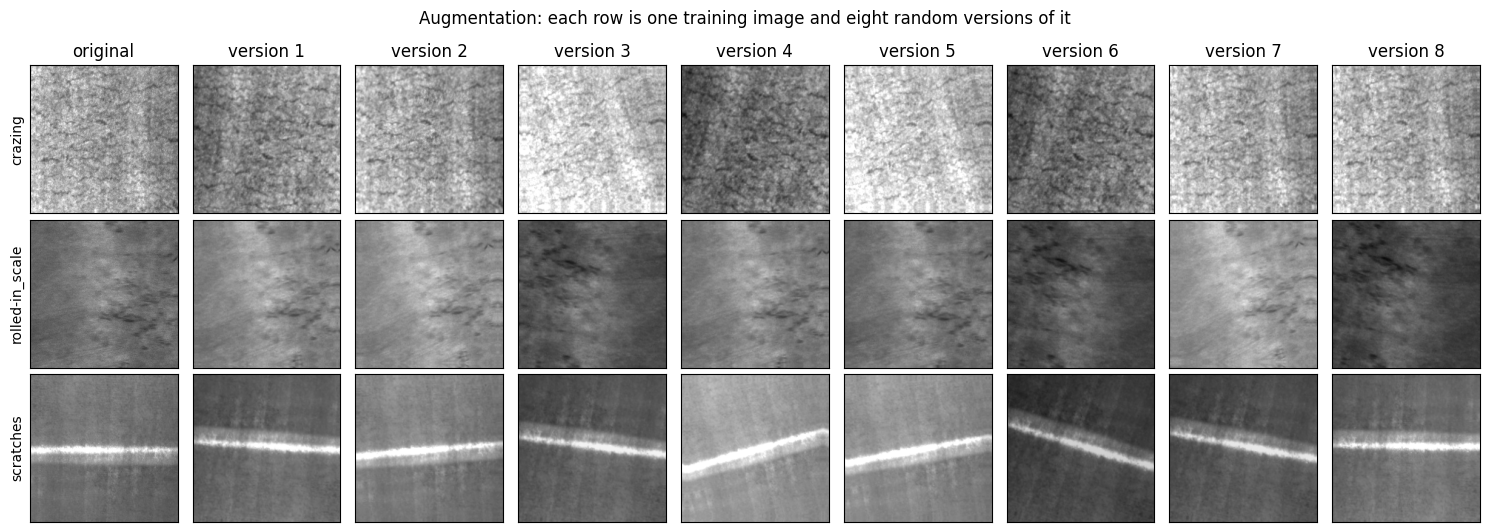

In [4]:
demo = pd.concat([splits["train"][splits["train"]["label"] == c].head(1) for c in ("crazing", "rolled-in_scale", "scratches")])
images, labels = next(iter(make_dataset(demo, 200)))

fig, axes = plt.subplots(len(demo), 9, figsize=(15, 5.4))
for row in range(len(demo)):
    original = images[row]
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title("original" if row == 0 else "")
    axes[row, 0].set_ylabel(CLASSES[int(labels[row])], fontsize=10)
    for col in range(1, 9):
        out = tf.clip_by_value(augment(original[None, ...], training=True)[0], 0.0, 1.0)
        axes[row, col].imshow(out[..., 0], cmap="gray", vmin=0, vmax=1)
        if row == 0:
            axes[row, col].set_title(f"version {col}")
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Augmentation: each row is one training image and eight random versions of it", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "prep_01_augmentation_examples.png", dpi=150)
plt.show()

## Leakage checklist

- [x] The split was made (notebook 02) before any augmentation.
- [x] Validation and test images are never augmented: the augmentation layers only run in training mode.
- [x] No picture is in two parts of the split (checked by an `assert` in notebook 02).
- [x] The test set has not been used for any decision: this notebook never loads it.

In [5]:
checks["batch_size"] = BATCH
checks["augmentation"] = [layer.name for layer in augment.layers]
checks["split_sizes"] = {name: int(len(part)) for name, part in splits.items()}
(RES_DIR / "pipeline_check.json").write_text(json.dumps(checks, indent=2))
print(json.dumps(checks, indent=2))

{
  "scratch_cnn": {
    "batch_shape": [
      32,
      200,
      200,
      1
    ],
    "min": 0.0,
    "max": 1.0,
    "labels_in_batch": [
      0,
      1,
      2,
      3,
      4,
      5
    ]
  },
  "mobilenetv2": {
    "batch_shape": [
      32,
      224,
      224,
      3
    ],
    "min": -0.997,
    "max": 1.0,
    "labels_in_batch": [
      0,
      1,
      2,
      3,
      4,
      5
    ]
  },
  "batch_size": 32,
  "augmentation": [
    "random_flip",
    "random_rotation",
    "random_zoom",
    "random_contrast",
    "random_brightness"
  ],
  "split_sizes": {
    "train": 1260,
    "val": 270,
    "test": 270
  }
}


## What we found

- One batch has the expected shapes: 32 × 200 × 200 × 1 with pixels from 0 to 1 for our own CNN, and 32 × 224 × 224 × 3 with pixels from −0.997 to 1 for MobileNetV2.
- Both first batches contain all six classes, so the shuffle mixes the classes well.
- The augmented versions in the figure still look like real steel: the scratch only tilts a little, the lighting changes, and the reflected corners blend in.